In [7]:
%pip install "aif360[LFR]" scikit-learn pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [8]:
# Import libraries
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

from aif360.sklearn.datasets import (
    fetch_adult,
    fetch_german,
    fetch_compas
)

from aif360.sklearn.preprocessing import LearnedFairRepresentations
from aif360.sklearn.metrics import consistency_score

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("Libraries imported successfully.")

pip install 'aif360[FairAdapt]'
pip install 'aif360[AdversarialDebiasing]'
pip install 'aif360[AdversarialDebiasing]'
pip install 'aif360[Reductions]'
pip install 'aif360[Reductions]'
pip install 'aif360[inFairness]'
pip install 'aif360[Reductions]'
pip install 'aif360[OptimalTransport]'


Libraries imported successfully.


In [9]:
import torch
from aif360.sklearn.preprocessing import LearnedFairRepresentations

print("PyTorch:", torch.__version__)
print("LFR is available!")

PyTorch: 2.15.0+cpu
LFR is available!


# Learning Fair Representations: Bias Mitigation Experiment

## Objective

The objective of this experiment is to evaluate Learning Fair Representations (LFR), a pre-processing bias mitigation algorithm introduced by Zemel et al. (2013).

LFR is applied to three datasets:
1. Adult Census Income
2. German Credit
3. COMPAS Recidivism

The experiment compares fairness and predictive performance before and after applying LFR.

## Evaluation metrics

- DP_Diff: Difference in positive prediction rates between the unprivileged and privileged groups.
- DIR: Ratio between the positive prediction rates of the unprivileged and privileged groups.
- Consistency: Measures whether similar individuals receive similar predictions.
- Accuracy: Measures the percentage of correct predictions.
- F1-score: Measures the balance between precision and recall.

A DP_Diff closer to zero and a DIR closer to one generally indicate better demographic parity.
A higher consistency score indicates better individual consistency.

In [10]:
print("Loading datasets...")

adult = fetch_adult(numeric_only=True)
german = fetch_german(numeric_only=True)
compas = fetch_compas(numeric_only=True)

print("All datasets loaded successfully.")

print("Adult:", adult.X.shape)
print("German:", german.X.shape)
print("COMPAS:", compas.X.shape)

Loading datasets...
All datasets loaded successfully.
Adult: (48842, 7)
German: (1000, 9)
COMPAS: (6172, 8)


In [11]:
# Set up datasets
datasets = {
    "Adult": {
        "data": adult,
        "privileged_group": 1
    },
    "German": {
        "data": german,
        "privileged_group": 1
    },
    "COMPAS": {
        "data": compas,
        "privileged_group": 1
    }
}

MAX_ROWS = 5000

print("Dataset settings prepared.")

Dataset settings prepared.


In [12]:
# Create metric functions
def get_sensitive_attribute(X, attribute="sex"):
    """
    Get the protected attribute from the DataFrame index.
    """
    if isinstance(X.index, pd.MultiIndex):
        if attribute in X.index.names:
            return pd.Series(
                X.index.get_level_values(attribute),
                index=X.index
            )

    if X.index.name == attribute:
        return pd.Series(X.index, index=X.index)

    raise ValueError(
        f"Could not find '{attribute}' in the dataset index. "
        f"Index names are: {X.index.names}"
    )


def fairness_metrics(y, sensitive, privileged_group=1):
    """
    Calculate DP_Diff and DIR.
    DP_Diff = unprivileged selection rate - privileged selection rate.
    DIR = unprivileged selection rate / privileged selection rate.
    """

    y = np.asarray(y).ravel()
    sensitive = np.asarray(sensitive).ravel()

    privileged_mask = sensitive == privileged_group
    unprivileged_mask = sensitive != privileged_group

    privileged_rate = np.mean(y[privileged_mask])
    unprivileged_rate = np.mean(y[unprivileged_mask])

    dp_diff = unprivileged_rate - privileged_rate

    if privileged_rate == 0:
        dir_value = np.nan
    else:
        dir_value = unprivileged_rate / privileged_rate

    return dp_diff, dir_value


def make_binary_labels(y, dataset_name):
    """
    Convert each dataset's favourable outcome into 1
    and its unfavourable outcome into 0.
    """

    y = pd.Series(np.asarray(y).ravel()).astype(str).str.lower().str.strip()

    if dataset_name == "Adult":
        return y.str.contains(">50k").astype(int)

    elif dataset_name == "German":
        return y.str.contains("good").astype(int)

    elif dataset_name == "COMPAS":
        return y.str.contains("survived").astype(int)

    else:
        raise ValueError("Unknown dataset.")

In [13]:
for name, settings in datasets.items():
    data = settings["data"]

    print("\n", name)
    print("Original labels:")
    print(pd.Series(np.asarray(data.y).ravel()).value_counts())


 Adult
Original labels:
0    37155
1    11687
Name: count, dtype: int64

 German
Original labels:
1    700
0    300
Name: count, dtype: int64

 COMPAS
Original labels:
0    3363
1    2809
Name: count, dtype: int64


In [14]:
# Run the experiment
results = []

for dataset_name, settings in datasets.items():

    print("\n" + "=" * 50)
    print("DATASET:", dataset_name)
    print("=" * 50)

    # 1. Load features and labels
    data = settings["data"]

    X = data.X.copy()
    X = data.X.copy()

    # The AIF360 datasets already have binary labels (0 and 1)
    y = pd.Series(
        np.asarray(data.y).ravel(),
        index=X.index
    ).astype(int)

    if y.nunique() != 2:
        raise ValueError(
            f"{dataset_name} does not contain both classes 0 and 1."
        )

    print("Label distribution:")
    print(y.value_counts())

    privileged_group = settings["privileged_group"]

    # 2. Keep a stratified sample if the dataset is large
    if len(X) > MAX_ROWS:
        X, _, y, _ = train_test_split(
            X,
            y,
            train_size=MAX_ROWS,
            stratify=y,
            random_state=RANDOM_STATE
        )

    # Get protected attribute
    sensitive = get_sensitive_attribute(X)

    # 3. Calculate fairness on original labels BEFORE training
    original_dp, original_dir = fairness_metrics(
        y,
        sensitive,
        privileged_group
    )

    original_consistency = consistency_score(
        StandardScaler().fit_transform(X),
        y,
        n_neighbors=5
    )

    print("Original label fairness calculated.")

    # 4. Stratified train/test split
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        stratify=y,
        random_state=RANDOM_STATE
    )

    sensitive_test = get_sensitive_attribute(X_test)

    # 5. Scale the original features
    scaler = StandardScaler()

    X_train_scaled = pd.DataFrame(
        scaler.fit_transform(X_train),
        columns=X_train.columns,
        index=X_train.index
    )

    X_test_scaled = pd.DataFrame(
        scaler.transform(X_test),
        columns=X_test.columns,
        index=X_test.index
    )

    # 6. Train baseline classifier WITHOUT LFR
    baseline_model = LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    )

    baseline_model.fit(X_train_scaled, y_train)

    baseline_predictions = baseline_model.predict(X_test_scaled)

    baseline_accuracy = accuracy_score(
        y_test,
        baseline_predictions
    )

    baseline_f1 = f1_score(
        y_test,
        baseline_predictions,
        zero_division=0
    )

    baseline_dp, baseline_dir = fairness_metrics(
        baseline_predictions,
        sensitive_test,
        privileged_group
    )

    baseline_consistency = consistency_score(
        X_test_scaled,
        baseline_predictions,
        n_neighbors=5
    )

    # 7. Apply LFR to the training data
    print("Applying LFR...")

    lfr = LearnedFairRepresentations(
        prot_attr="sex",
        n_prototypes=5,
        reconstruct_weight=0.01,
        target_weight=1.0,
        fairness_weight=50.0,
        max_iter=100,
        random_state=RANDOM_STATE
    )

    lfr.fit(
        X_train_scaled,
        y_train,
        priv_group=privileged_group
    )

    # Transform training and test features using the fitted LFR
    X_train_lfr = lfr.transform(X_train_scaled)
    X_test_lfr = lfr.transform(X_test_scaled)

    # 8. Train classifier on transformed features
    lfr_model = LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    )

    lfr_model.fit(X_train_lfr, y_train)

    lfr_predictions = lfr_model.predict(X_test_lfr)

    # 9. Evaluate predictive performance after LFR
    lfr_accuracy = accuracy_score(
        y_test,
        lfr_predictions
    )

    lfr_f1 = f1_score(
        y_test,
        lfr_predictions,
        zero_division=0
    )

    # 10. Evaluate fairness after LFR
    lfr_dp, lfr_dir = fairness_metrics(
        lfr_predictions,
        sensitive_test,
        privileged_group
    )

    lfr_consistency = consistency_score(
        X_test_lfr,
        lfr_predictions,
        n_neighbors=5
    )

    # 11. Store all results
    results.append({
        "Dataset": dataset_name,
        "Evaluation": "Original labels",
        "DP_Diff": original_dp,
        "DIR": original_dir,
        "Consistency": original_consistency,
        "Accuracy": np.nan,
        "F1": np.nan
    })

    results.append({
        "Dataset": dataset_name,
        "Evaluation": "Baseline classifier",
        "DP_Diff": baseline_dp,
        "DIR": baseline_dir,
        "Consistency": baseline_consistency,
        "Accuracy": baseline_accuracy,
        "F1": baseline_f1
    })

    results.append({
        "Dataset": dataset_name,
        "Evaluation": "LFR classifier",
        "DP_Diff": lfr_dp,
        "DIR": lfr_dir,
        "Consistency": lfr_consistency,
        "Accuracy": lfr_accuracy,
        "F1": lfr_f1
    })

    print("Baseline accuracy:", round(baseline_accuracy, 3))
    print("LFR accuracy:", round(lfr_accuracy, 3))
    print("LFR experiment completed.")


DATASET: Adult
Label distribution:
0    37155
1    11687
Name: count, dtype: int64
Original label fairness calculated.
Applying LFR...
Baseline accuracy: 0.824
LFR accuracy: 0.762
LFR experiment completed.

DATASET: German
Label distribution:
1    700
0    300
Name: count, dtype: int64
Original label fairness calculated.
Applying LFR...
Baseline accuracy: 0.715
LFR accuracy: 0.7
LFR experiment completed.

DATASET: COMPAS
Label distribution:
0    3363
1    2809
Name: count, dtype: int64
Original label fairness calculated.
Applying LFR...
Baseline accuracy: 0.659
LFR accuracy: 0.596
LFR experiment completed.


,Dataset,Evaluation,DP_Diff,DIR,Consistency,Accuracy,F1
0,Adult,Original labels,-0.1994,0.3441,0.8124,NaN,NaN
1,Adult,Baseline classifier,-0.1568,0.1275,0.9628,0.824,0.5165
2,Adult,LFR classifier,-0.0015,0.0000,0.9986,0.762,0.0083
3,German,Original labels,-0.0748,0.8966,0.7012,NaN,NaN
4,German,Baseline classifier,-0.0738,0.9229,0.9430,0.715,0.8257
5,German,LFR classifier,0.0000,1.0000,1.0000,0.700,0.8235
6,COMPAS,Original labels,0.1315,1.3771,0.6504,NaN,NaN
7,COMPAS,Baseline classifier,0.2808,3.1422,0.9778,0.659,0.5785
8,COMPAS,LFR classifier,0.0589,2.0107,0.9816,0.596,0.2786


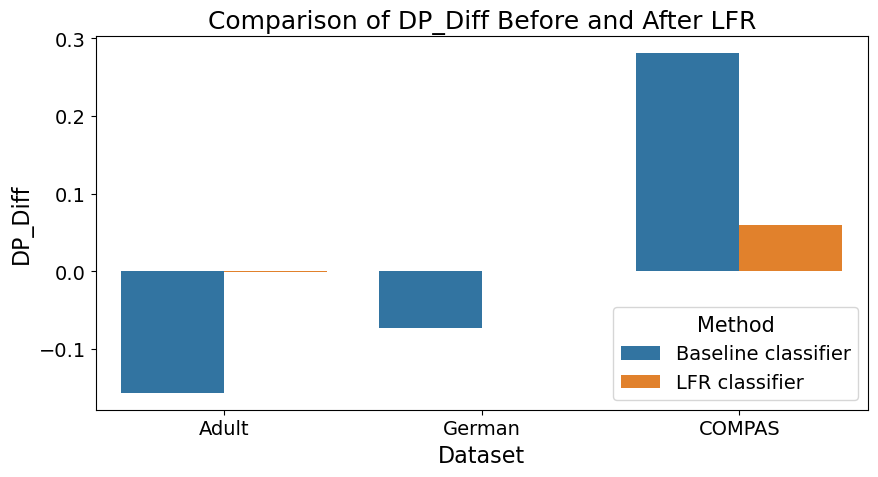

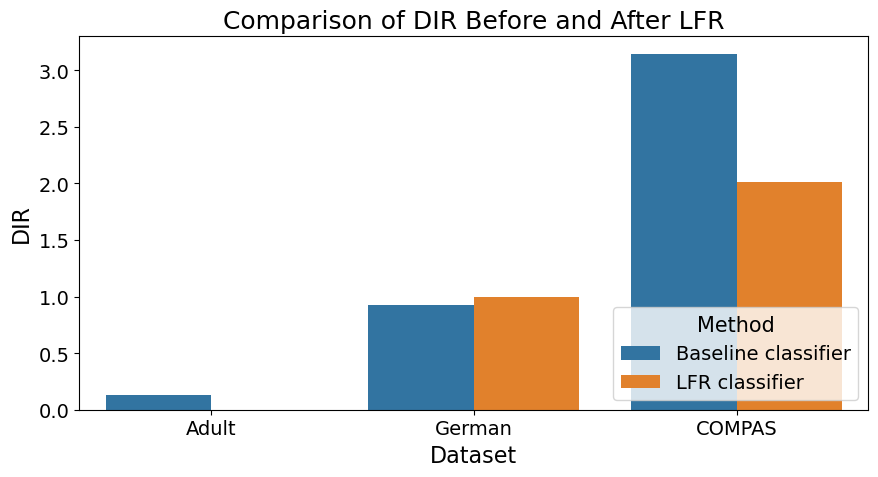

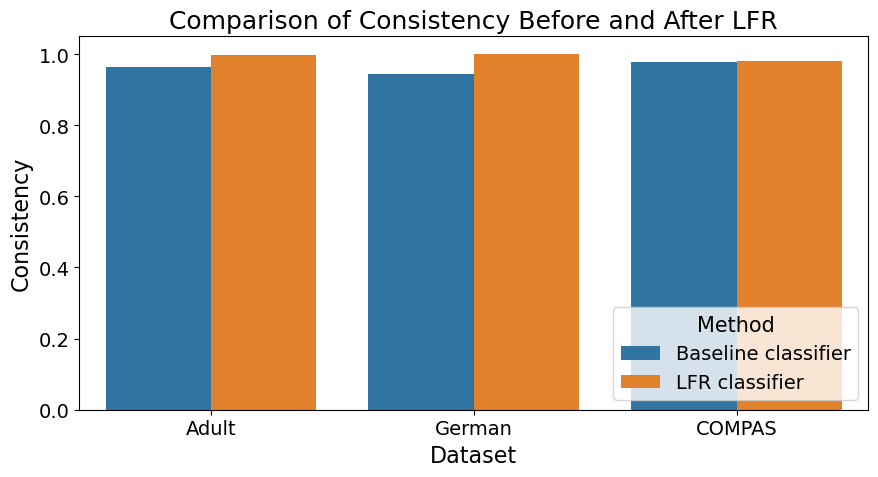

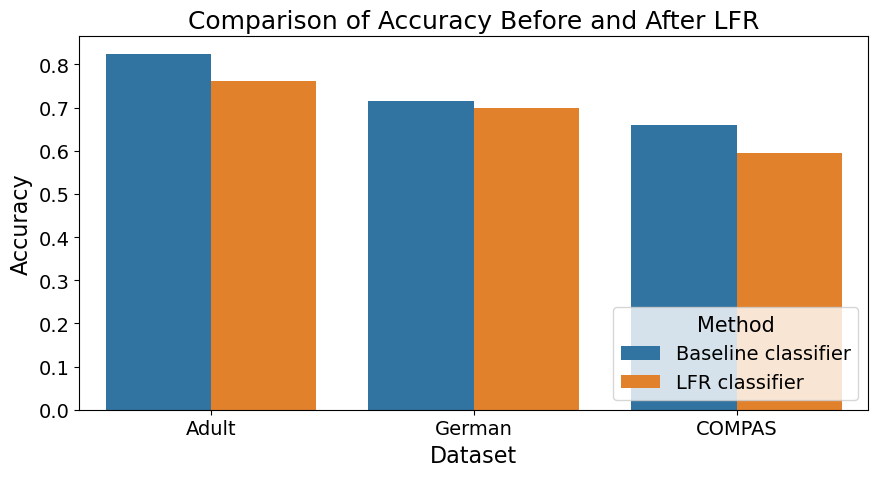

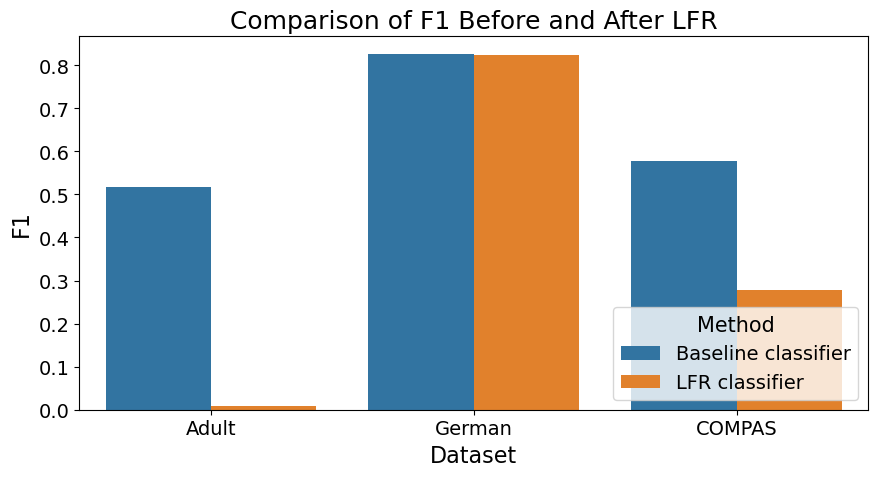

LaTeX table saved successfully!


In [23]:
import pandas as pd
# Display the results 
results_df = pd.DataFrame(results)

results_df = results_df.round(4)

display(results_df)

import matplotlib.pyplot as plt
import seaborn as sns


# Select the two classifier evaluations
plot_data = results_df[
    results_df["Evaluation"].isin([
        "Baseline classifier",
        "LFR classifier"
    ])
]

metrics = [
    "DP_Diff",
    "DIR",
    "Consistency",
    "Accuracy",
    "F1"
]

# Increase font sizes for all graphs
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "legend.title_fontsize": 15,
    "figure.titlesize": 20
})

# Create one histogram for each metric
for metric in metrics:

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=plot_data,
        x="Dataset",
        y=metric,
        hue="Evaluation"
    )

    plt.title(f"Comparison of {metric} Before and After LFR")
    plt.xlabel("Dataset")
    plt.ylabel(metric)
    plt.legend(title="Method", loc="lower right")
    plt.tight_layout()
    plt.savefig(f"histogram_{metric}")

    plt.show()
    

# Create a clean LaTeX table
latex_table = results_df.to_latex(
    index=False,
    float_format="%.4f",
    caption="Fairness and predictive performance before and after LFR.",
    label="tab:lfr_results",
    na_rep="-"
)

# Save the LaTeX file
with open("LFR_results.tex", "w", encoding="utf-8") as file:
    file.write(latex_table)

print("LaTeX table saved successfully!")

In [16]:
# Compare baseline and LFR results
comparison = results_df[
    results_df["Evaluation"].isin([
        "Baseline classifier",
        "LFR classifier"
    ])
]

comparison = comparison.pivot(
    index="Dataset",
    columns="Evaluation",
    values=["DP_Diff", "DIR", "Consistency", "Accuracy", "F1"]
)

display(comparison.round(4))

DP_Diff                                DIR  \
Evaluation Baseline classifier LFR classifier Baseline classifier   
Dataset                                                             
Adult                  -0.1568        -0.0015              0.1275   
COMPAS                  0.2808         0.0589              3.1422   
German                 -0.0738         0.0000              0.9229   

                                  Consistency                 \
Evaluation LFR classifier Baseline classifier LFR classifier   
Dataset                                                        
Adult              0.0000              0.9628         0.9986   
COMPAS             2.0107              0.9778         0.9816   
German             1.0000              0.9430         1.0000   

                      Accuracy                                 F1  \
Evaluation Baseline classifier LFR classifier Baseline classifier   
Dataset                                                             
Adult                    0.824          0.762              0.5165   
COMPAS                   0.659          0.596              0.5785   
German                   0.715          0.700              0.8257   

                           
Evaluation LFR classifier  
Dataset                    
Adult              0.0083  
COMPAS             0.2786  
German             0.8235

In [17]:
# Save the results to csv file
results_df.to_csv("LFR_results.csv", index=False)

print("Results saved as LFR_results.csv")

Results saved as LFR_results.csv


In [18]:
# Interpretation
for dataset_name in datasets.keys():

    baseline = results_df[
        (results_df["Dataset"] == dataset_name) &
        (results_df["Evaluation"] == "Baseline classifier")
    ].iloc[0]

    mitigated = results_df[
        (results_df["Dataset"] == dataset_name) &
        (results_df["Evaluation"] == "LFR classifier")
    ].iloc[0]

    print("\n", dataset_name)

    print(
        "Absolute DP_Diff before:",
        round(abs(baseline["DP_Diff"]), 4)
    )

    print(
        "Absolute DP_Diff after:",
        round(abs(mitigated["DP_Diff"]), 4)
    )

    print(
        "Accuracy before:",
        round(baseline["Accuracy"], 4)
    )

    print(
        "Accuracy after:",
        round(mitigated["Accuracy"], 4)
    )

    if abs(mitigated["DP_Diff"]) < abs(baseline["DP_Diff"]):
        print("Demographic parity improved after LFR.")
    else:
        print("Demographic parity did not improve after LFR.")





 Adult
Absolute DP_Diff before: 0.1568
Absolute DP_Diff after: 0.0015
Accuracy before: 0.824
Accuracy after: 0.762
Demographic parity improved after LFR.

 German
Absolute DP_Diff before: 0.0738
Absolute DP_Diff after: 0.0
Accuracy before: 0.715
Accuracy after: 0.7
Demographic parity improved after LFR.

 COMPAS
Absolute DP_Diff before: 0.2808
Absolute DP_Diff after: 0.0589
Accuracy before: 0.659
Accuracy after: 0.596
Demographic parity improved after LFR.
